# τ → μγ and τ → eγ in the soft-broken 3HDM-S₃

**A research notebook, not a tutorial.** It follows notebook 07 (μ→eγ) and completes the
three radiative LFV decays $\ell_i\to\ell_j\gamma$ on the same 2028 viable soft points. The
questions:

> Do the τ modes cut the scalar sector beyond what MEG II already cuts? How does τ→μγ
> compare with $h\to\tau\mu$, which bounds the lepton dial $\mu_3^\ell$? And because
> τ→μγ, unlike μ→eγ, is **allowed** at the exact-S₃ vacuum, does it bound the exact points?

Limits at 90% CL: $\mathcal B(\tau\to\mu\gamma)<4.2\times10^{-8}$ (Belle, 988 fb⁻¹
[Belle21]) and $\mathcal B(\tau\to e\gamma)<3.3\times10^{-8}$ (BaBar [BaBar10], stronger
than Belle's $5.6\times10^{-8}$).

**What changes from notebook 07: only indices.** The diagrams are the same (one loop with
$h_{1,2,3}$, $A_{1,2}$, $H^\pm_{1,2}$; Barr–Zee with quark (ansatz), τ, $W$ and $H^\pm$ loops).
`radiative.py` now takes the decaying lepton $i$ and the final one $j$, and
`soft_decays.lfv_radiative(…, i, j)` assembles any channel; `mu_e_gamma` is its $(\mu,e)$
case. Two things are new physics rather than plumbing:

- the internal-τ chirality flip, the dominant one-loop term of μ→eγ ($\propto m_\tau/m_\mu$),
  is **not enhanced** for a decaying τ ($m_\tau/m_\tau$, times a log);
- $\Gamma(\tau\to\ell\gamma)$ is normalized to $\Gamma(\tau\to\ell\nu\bar\nu)$ and multiplied by
  its branching ratio [OST16] Eq. (17).

§1 checks the generalization, §2 the τ normalization and the literature oracles, §3 is the
exact-S₃ vacuum (the headline), §4 the S₃ image, §5 the soft scan and §6 the deliverable.

In [ ]:
import json, logging, math, sys, time
from pathlib import Path

import numpy as np
import sympy as sp
import matplotlib
logging.getLogger("matplotlib").setLevel(logging.CRITICAL)  # a broken personal
import matplotlib.pyplot as plt                             # stylelib file is noisy
from scipy.integrate import quad

sys.path.insert(0, str(Path.cwd()))
import soft_decays as S
import lfv
import decays as D
import radiative as RD
from model import V_EW
from sm_inputs import (ALPHA, G_F, M_W, M_T, GAMMA_H_SM, BR_TAU_ENUNU, BR_TAU_MUNUNU,
                       TAU_LIFETIME, HBAR_GEV_S)
import derive as dv

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
sp.init_printing(use_latex="mathjax")
ok = dv.ok
C_BLUE, C_RED, C_GREEN, C_GREY = "#4C72B0", "#C44E52", "#55A868", "#8C8C8C"


def check_quoted(section, rows):
    "Assert that the numbers the markdown quotes still match this run."
    stale = [(what, got, want) for what, got, want, tol in rows if abs(float(got) - float(want)) > tol]
    assert not stale, "§%s prose is stale (what, computed, quoted): %s" % (section, stale)
    ok("the %d numbers quoted in §%s match this run" % (len(rows), section))


ledger = dv.Ledger("08 — the radiative decays of the tau in the soft-broken vacuum")
ME, MMU, MTAU = lfv.LEPTON_MASSES
masses_t = np.array(lfv.LEPTON_MASSES)
E, MU, TAU = RD.E, RD.MU, RD.TAU
CH = S.RADIATIVE_CHANNELS                              # name: (i, j, limit)
LIM = {k: v[2] for k, v in CH.items()}
LIMIT = {f"{a}{b}": lim for (a, b), lim in D.LFV_LIMITS.items()}
PAIRS = {"taumu": (2, 1), "taue": (2, 0), "emu": (0, 1)}
SOFT0 = {n: 0.0 for n in ("mD1sq", "mD2sq", "mS1sq", "mS2sq")}

t0 = time.time()
T = S.build_tools()
points = json.loads(Path("results/viable_points_soft.json").read_text())["points"]
grid = np.linspace(-0.9995 * MTAU, 0.9995 * MTAU, 73)   # notebook 06's mu_3 grid
rots = [S.point_rotations(T, p) for p in points]
print("soft model + %d viable soft points rebuilt in %.1f s" % (len(points), time.time() - t0))
for k, (i, j, lim) in CH.items():
    print("  %-6s i = %d -> j = %d, limit %.1e" % (k, i, j, lim))

soft model + 2028 viable soft points rebuilt in 3.3 s
  mu_e   i = 1 -> j = 0, limit 1.5e-13
  tau_mu i = 2 -> j = 1, limit 4.2e-08
  tau_e  i = 2 -> j = 0, limit 3.3e-08


---
## 1. The generalization to $\ell_i\to\ell_j\gamma$

[HKZ13] Eq. (A3) is written for τ→μγ; notebook 07 coded it for $(i,j)=(\mu,e)$. In general

$$c_L=\sum_f\frac{\tfrac12I_1(t_f)\,(m_jY_{jf}Y^*_{if}+m_iY^*_{fj}Y_{fi})+I_2(t_f)\,m_fY^*_{fj}Y^*_{if}}{4m_im_\phi^2},
\qquad A=c/4\pi^2,$$

the charged loop is $A_L=-(Y_C^\dagger Y_C)_{ji}/(192\pi^2m_{H^\pm}^2)$, and the Barr–Zee terms
take $(Y_{ij},Y_{ji})$ and $1/m_i$ in place of $(Y_{\mu e},Y_{e\mu})$ and $1/m_\mu$.

**Check 1: regression.** With $(i,j)=(\mu,e)$ the refactored `lfv_radiative` must give back
notebook 07's stored result: the least-constrained $\mathcal B(\mu\to e\gamma)$ of each point
in `results/mu_e_gamma.json` (4 significant figures).

In [ ]:
stored = json.loads(Path("results/mu_e_gamma.json").read_text())["points"]
probe_reg = np.random.default_rng(3).choice(len(points), 25, replace=False)
worst_reg = 0.0
for i in probe_reg:
    p, r = points[i], rots[i]
    g = S.hhh_charged(T, p, r)
    brs = [S.lfv_radiative(T, p, r, b["Y"], MU, E, g)["br"]
           for c in grid for b in lfv.lepton_branches(T.g_of, c, r["vevs"])]
    if stored[i]["best"] is None:
        assert not brs
        continue
    worst_reg = max(worst_reg, abs(min(brs) / stored[i]["best"]["br"] - 1))
print("max |B_min(new) / B_min(notebook 07) - 1| over %d points: %.1e  (stored to 4 figures)" % (len(probe_reg), worst_reg))
assert worst_reg < 1e-3
ok("lfv_radiative(mu, e) reproduces notebook 07's mu -> e gamma")

max |B_min(new) / B_min(notebook 07) - 1| over 25 points: 3.5e-04  (stored to 4 figures)
✓ lfv_radiative(mu, e) reproduces notebook 07's mu -> e gamma


**Check 2: relabelling.** Rename the flavours so that the old (τ, μ) sit in the slots the
μ→eγ code reads, $(e,\mu,\tau)\to(\mu,\tau,e)$: permute the rows and columns of every Yukawa
matrix and the mass vector. The default $(\mu,e)$ call on the relabelled inputs must equal
the $(\tau,\mu)$ call on the originals, and likewise for $(\tau,e)$. This tests that no
$e$/$\mu$ index survived in the general code, using the couplings of a real soft point.

In [ ]:
Y0 = next(b["Y"] for c in grid for b in lfv.lepton_branches(T.g_of, c, rots[0]["vevs"]))
masses_p, Yp0 = S.mass_basis_yukawas(T, Y0, rots[0])
worst_perm = 0.0
for (i, j), perm in (((TAU, MU), [MU, TAU, E]), ((TAU, E), [E, TAU, MU])):
    # new slot n holds old flavour perm[n]; slot MU must hold i and slot E must hold j
    assert perm[MU] == i and perm[E] == j
    P = np.ix_(perm, perm)
    for key in ("h1", "h2", "h3", "A1", "A2"):
        a = RD.one_loop_neutral(Yp0[key], masses_p, rots[0]["mass"][key], i=i, j=j)
        b = RD.one_loop_neutral(Yp0[key][P], masses_p[perm], rots[0]["mass"][key])
        worst_perm = max(worst_perm, max(abs(a[0] - b[0]), abs(a[1] - b[1])) / max(abs(a[0]), abs(a[1])))
    for key in ("Hpm1", "Hpm2"):
        a = RD.one_loop_charged(Yp0[key], rots[0]["mass"][key], i=i, j=j)
        b = RD.one_loop_charged(Yp0[key][P], rots[0]["mass"][key])
        worst_perm = max(worst_perm, abs(a[0] - b[0]) / abs(a[0]))
print("max relative difference, (tau -> l) on the originals vs (mu -> e) relabelled: %.1e" % worst_perm)
assert worst_perm < 1e-12
ok("the general one-loop code has no fixed e/mu index left")

max relative difference, (tau -> l) on the originals vs (mu -> e) relabelled: 3.0e-16
✓ the general one-loop code has no fixed e/mu index left


**Check 3: the one-loop closed form for a decaying τ, external masses kept.** The closed form
drops the external masses from the denominator. For μ→eγ that is $m_\mu^2/m_\phi^2$; for a
decaying τ and a *light* scalar it is $m_\tau^2/m_\phi^2$, which is $5\times10^{-3}$ at
25 GeV, and §3 will meet scalars that light. Repeat notebook 07's comparison against the
full two-parameter integral of [HKZ13] (A3) with $(i,j)=(\tau,\mu)$.

In [ ]:
def hkz_c(Y, masses, m_phi, i, j, left=True):
    "[HKZ13] Eq. (A3) for l_i -> l_j gamma summed over f, by 2D quadrature, external masses kept."
    Y = Y if left else Y.conj().T
    mi, mj = masses[i], masses[j]
    tot = 0j
    for f in range(3):
        mf = masses[f]
        nums = (mj * Y[j, f] * np.conj(Y[i, f]), mi * np.conj(Y[f, j]) * Y[f, i], mf * np.conj(Y[f, j]) * np.conj(Y[i, f]))
        for part, wfun in zip(nums, (lambda x, z: x * z, lambda x, z: (1 - z - x) * z, lambda x, z: 1 - z)):
            def inner(z):
                den = lambda x: (z * m_phi**2 - x * z * mj**2 - (1 - z - x) * z * mi**2 + (1 - z) * mf**2)
                return quad(lambda x: wfun(x, z) / den(x), 0, 1 - z, epsrel=1e-11)[0]
            val = quad(inner, 0, 1, points=[1e-10, 1e-8, 1e-6, 1e-4, 1e-2], limit=400, epsrel=1e-10)[0]
            tot += part * val
    return tot / (4 * mi)


rng = np.random.default_rng(8)
Yr = (rng.normal(size=(3, 3)) + 1j * rng.normal(size=(3, 3))) * 1e-3
rel_tau = {}
for m_phi in (700.0, 25.0):
    AL, AR = RD.one_loop_neutral(Yr, masses_t, m_phi, i=TAU, j=MU)
    cL, cR = hkz_c(Yr, masses_t, m_phi, TAU, MU), hkz_c(Yr, masses_t, m_phi, TAU, MU, left=False)
    rel_tau[m_phi] = max(abs(4 * math.pi**2 * AL / cL - 1), abs(4 * math.pi**2 * AR / cR - 1))
    print("m_phi = %5.0f GeV: |4pi^2 A / c_HKZ - 1| = %.1e   (m_tau^2/m_phi^2 = %.0e)"
          % (m_phi, rel_tau[m_phi], MTAU**2 / m_phi**2))
assert rel_tau[700.0] < 1e-4 and rel_tau[25.0] < 2e-2
ok("closed form = [HKZ13] (A3) for tau -> mu gamma: exact at 700 GeV, %.1f%% at 25 GeV" % (100 * rel_tau[25.0]))

m_phi =   700 GeV: |4pi^2 A / c_HKZ - 1| = 2.8e-06   (m_tau^2/m_phi^2 = 6e-06)


m_phi =    25 GeV: |4pi^2 A / c_HKZ - 1| = 1.7e-03   (m_tau^2/m_phi^2 = 5e-03)
✓ closed form = [HKZ13] (A3) for tau -> mu gamma: exact at 700 GeV, 0.2% at 25 GeV


**Check 4: [OST16] Eq. (19).** For τ→μγ with only the internal τ, [OST16] write the one loop
explicitly:
$A_L=\dfrac{y^*_{\tau\mu}}{16\pi^2m_\phi^2}\Big[y^*_{\tau\tau}\big(\log\tfrac{m_\phi^2}{m_\tau^2}-\tfrac32\big)+\tfrac{y_{\tau\tau}}{6}\Big]$.
Here the flip and non-flip terms carry the same mass, so this is also the check that the
general code puts $m_i$ and $m_f$ in the right places (notebook 07 found [OST16]'s μ→eγ
Eq. (30) misplaces one; Eq. (19) is the form that agrees with [HKZ13]).

In [ ]:
def ost19(Y, m_phi):
    return np.conj(Y[2, 1]) / (16 * math.pi**2 * m_phi**2) * (np.conj(Y[2, 2]) * (math.log(m_phi**2 / MTAU**2) - 1.5) + Y[2, 2] / 6)


Yo = np.zeros((3, 3), complex)
Yo[2, 1], Yo[2, 2] = 0.01 + 0.003j, 0.02 - 0.01j
rel_ost = max(abs(RD.one_loop_neutral(Yo, masses_t, m, i=TAU, j=MU)[0] / ost19(Yo, m) - 1) for m in (300.0, 1000.0))
print("max |A_L / [OST16] (19) - 1| at m_phi = 300, 1000 GeV: %.1e  (O(m_tau^2/m_phi^2) terms)" % rel_ost)
assert rel_ost < 1e-3
ok("the general one loop reproduces [OST16] Eq. (19) for tau -> mu gamma")
dv.falsify("the internal-tau flip carrying m_tau/m_mu as in mu -> e gamma",
           lambda: abs(RD.one_loop_neutral(Yo, masses_t, 300.0, i=TAU, j=MU)[0] * MTAU / MMU / ost19(Yo, 300.0) - 1) < 1e-3)

max |A_L / [OST16] (19) - 1| at m_phi = 300, 1000 GeV: 1.0e-04  (O(m_tau^2/m_phi^2) terms)
✓ the general one loop reproduces [OST16] Eq. (19) for tau -> mu gamma
✓ the internal-tau flip carrying m_tau/m_mu as in mu -> e gamma — the check fires on a broken input, so it has teeth


True

---
## 2. The τ normalization and the literature oracles

### 2.1 $\Gamma(\tau\to\ell\gamma)$ over $\Gamma(\tau\to\ell\nu\bar\nu)$

$\mathcal B(\tau\to\ell\gamma)=\dfrac{48\pi^3\alpha(|A_L|^2+|A_R|^2)}{G_F^2}\,\mathcal B(\tau\to\ell\nu\bar\nu)$
([OST16] Eq. (17)): the ratio to $\Gamma(\tau\to\ell\nu\bar\nu)=G_F^2m_\tau^5/192\pi^3$, which
for the muon was the whole width. The alternative is to divide
$\Gamma=\alpha m_\tau^5(|A_L|^2+|A_R|^2)/4$ by $\hbar/\tau_\tau$, as [HKZ13] Eq. (15) does.
They agree if $G_F^2m_\tau^5\tau_\tau/(192\pi^3\hbar)$ reproduces the measured leptonic
branching ratio, up to phase space ($f(m_\mu^2/m_\tau^2)=0.973$ for the muon) and radiative
corrections.

In [ ]:
br_e_pred = G_F**2 * MTAU**5 / (192 * math.pi**3) * TAU_LIFETIME / HBAR_GEV_S
xm = (MMU / MTAU) ** 2
f_mu = 1 - 8 * xm + 8 * xm**3 - xm**4 - 12 * xm**2 * math.log(xm)
print("G_F^2 m_tau^5 tau_tau / 192 pi^3 hbar = %.4f   (PDG B(tau -> e nu nu) = %.4f)" % (br_e_pred, BR_TAU_ENUNU))
print("  x f(m_mu^2/m_tau^2) = %.4f                  (PDG B(tau -> mu nu nu) = %.4f)" % (br_e_pred * f_mu, BR_TAU_MUNUNU))
dev_norm = max(abs(br_e_pred / BR_TAU_ENUNU - 1), abs(br_e_pred * f_mu / BR_TAU_MUNUNU - 1))
assert dev_norm < 0.01
ok("the two tau normalizations agree to %.1f%%" % (100 * dev_norm))

G_F^2 m_tau^5 tau_tau / 192 pi^3 hbar = 0.1786   (PDG B(tau -> e nu nu) = 0.1782)
  x f(m_mu^2/m_tau^2) = 0.1737                  (PDG B(tau -> mu nu nu) = 0.1739)
✓ the two tau normalizations agree to 0.2%


### 2.2 The oracle: [HKZ13]'s τ→μγ and τ→eγ bounds

With only $Y_{\tau\ell}$, $Y_{\ell\tau}$ switched on, SM diagonal couplings, $Y_{tt}=\bar m_t/v$
($\bar m_t=164$ GeV) and $m_h=125$ GeV, [HKZ13] translate
$\mathcal B(\tau\to\mu\gamma)<4.4\times10^{-8}$ and $\mathcal B(\tau\to e\gamma)<3.3\times10^{-8}$
into $\sqrt{|Y_{\tau\mu}|^2+|Y_{\mu\tau}|^2}<0.016$ and $\sqrt{|Y_{\tau e}|^2+|Y_{e\tau}|^2}<0.014$
(their Table I and the text below Eq. (15)). Unlike μ→eγ, the one loop is comparable to the
two loop here ("for τ→eγ the two loop and one loop contributions are comparable"), so this
oracle tests the relative sign of the one- and two-loop pieces as well as the
normalization. Notebook 07 §2.3 found the coded $W$ loop 14% above [HKZ13]'s number; the
comparison is made with the $W$ loop scaled to theirs, and the unscaled bound is printed too.

In [ ]:
mt_bar, mh = 164.0, 125.0
bz_ref = RD.barr_zee(1.0, 0.0, mh, ALPHA, 246.0, m_w=M_W, kappa_w=1.0, fermions=[(3, 2 / 3, mt_bar, 1.0)], m_mu=MTAU)
c_w = (4 * math.pi**2 * bz_ref["W"][0] * mh**2).real
W_HKZ = 0.11 / c_w                     # [HKZ13]'s W number over ours (notebook 07 section 2.3)


def sm_higgs_br(i, j, y, w_scale=1.0, sign_2loop=1.0, ytt=mt_bar / 246.0, m_top=mt_bar, v=246.0):
    Yh = np.diag(masses_t / v).astype(complex)
    Yh[i, j] = y
    AL, AR = RD.one_loop_neutral(Yh, masses_t, mh, i=i, j=j)
    p = RD.barr_zee(Yh[i, j], Yh[j, i], mh, ALPHA, v, m_w=M_W, kappa_w=1.0,
                    fermions=[(3, 2 / 3, m_top, ytt)], m_mu=masses_t[i])
    AL += sign_2loop * (p["fermion"][0] + w_scale * p["W"][0])
    AR += sign_2loop * (p["fermion"][1] + w_scale * p["W"][1])
    return RD.branching_ratio(AL, AR, ALPHA, G_F, S.TAU_BR_LNN[j])


def bound(i, j, lim, **kw):
    return 1e-3 * math.sqrt(lim / sm_higgs_br(i, j, 1e-3, **kw))


hkz = {"tau_mu": (TAU, MU, 4.4e-8, 0.016), "tau_e": (TAU, E, 3.3e-8, 0.014)}
rel_hkz = {}
for name, (i, j, lim_old, quoted) in hkz.items():
    b_hkz, b_raw = bound(i, j, lim_old, w_scale=W_HKZ), bound(i, j, lim_old)
    rel_hkz[name] = abs(b_hkz / quoted - 1)
    print("%-6s at B < %.1e: %.4f with [HKZ13]'s W, %.4f with ours   ([HKZ13]: %.3f)" % (name, lim_old, b_hkz, b_raw, quoted))
# [HKZ13] quote two figures; agreement within their rounding (0.0155-0.0165, 0.0135-0.0145)
assert rel_hkz["tau_mu"] < 0.035 and rel_hkz["tau_e"] < 0.04
ok("the assembled tau rates reproduce both [HKZ13] bounds within their rounding")
dv.falsify("the two-loop pieces with the opposite sign to the one loop",
           lambda: abs(bound(TAU, MU, 4.4e-8, w_scale=W_HKZ, sign_2loop=-1) / 0.016 - 1) < 0.035)

cur = {name: bound(i, j, LIM[name], ytt=M_T / V_EW, m_top=M_T, v=V_EW) for name, (i, j, _, _) in hkz.items()}
print("\nat the current limits and pole m_t, an SM-like Higgs needs")
print("  sqrt(|Y_taumu|^2 + |Y_mutau|^2) < %.4f   (Belle 2021)" % cur["tau_mu"])
print("  sqrt(|Y_taue|^2  + |Y_etau|^2)  < %.4f   (BaBar 2010)" % cur["tau_e"])
# the h -> tau mu limit on the same combination: B = m_h/8pi (|Y|^2+|Y|^2) / Gamma_h^SM
y_h = {q: math.sqrt(LIMIT[q] * GAMMA_H_SM * 8 * math.pi / mh) for q in ("taumu", "taue")}
print("while CMS h -> tau mu, tau e need < %.4f, %.4f: the Higgs decay is %.0fx, %.0fx stronger in the coupling"
      % (y_h["taumu"], y_h["taue"], cur["tau_mu"] / y_h["taumu"], cur["tau_e"] / y_h["taue"]))

tau_mu at B < 4.4e-08: 0.0159 with [HKZ13]'s W, 0.0130 with ours   ([HKZ13]: 0.016)
tau_e  at B < 3.3e-08: 0.0136 with [HKZ13]'s W, 0.0112 with ours   ([HKZ13]: 0.014)
✓ the assembled tau rates reproduce both [HKZ13] bounds within their rounding
✓ the two-loop pieces with the opposite sign to the one loop — the check fires on a broken input, so it has teeth

at the current limits and pole m_t, an SM-like Higgs needs
  sqrt(|Y_taumu|^2 + |Y_mutau|^2) < 0.0130   (Belle 2021)
  sqrt(|Y_taue|^2  + |Y_etau|^2)  < 0.0114   (BaBar 2010)
while CMS h -> tau mu, tau e need < 0.0011, 0.0013: the Higgs decay is 12x, 8x stronger in the coupling


For an SM-like Higgs the direct $h\to\tau\ell$ searches beat the radiative τ decays by an
order of magnitude in the coupling. This is the reverse of the $e\mu$ case, where MEG II
bounds the coupling at $7\times10^{-7}$ against CMS's $10^{-4}$ (notebook 07). The τ modes
can still matter where the Higgs decay is blind: LFV couplings of **non-SM** scalars, which
§3 finds.

---
## 3. The exact-S₃ vacuum: τ→eγ vanishes, τ→μγ does not

> **Predict.** Notebook 07 §3 traced the zero of μ→eγ to the residual $\mathbb Z_2$ of the
> aligned vacuum, under which the electron and the in-plane non-vacuum scalars ($h_0$, one
> $A$, one $H^\pm$) are odd and μ, τ even. What does it say about τ→eγ and τ→μγ?

τ→eγ has one odd lepton: forbidden, exactly like μ→eγ. τ→μγ has none: **allowed**, through
the $\mathbb Z_2$-even scalars. So the exact-S₃ points, which μ→eγ cannot test, meet their
first radiative constraint here. The coupling pattern behind this: the odd scalars have
$Y_{\tau\mu}=0$ and the even ones $Y_{\tau e}=Y_{e\mu}=0$.

As in notebook 07, each viable exact point of notebook 01 is evaluated with the soft
machinery at φ = π/3 and every free soft term zero, on the draft lepton branch
(`lfv.aligned_yukawas`), here over 60 values of $\mu_3\in(m_\mu,m_\tau)$, the draft's whole
range.

In [ ]:
exact_pts = D.load_points()
grid_exact = np.linspace(MMU, MTAU, 62)[1:-1]


def z2_pattern(Yp, tol):
    "(odd states, even states) by their couplings: odd have no tau-mu, even have no e-anything."
    odd = [k for k in ("h1", "h2", "h3", "A1", "A2", "Hpm1", "Hpm2")
           if abs(Yp[k][TAU, MU]) + abs(Yp[k][MU, TAU]) < tol]
    even = [k for k in ("h1", "h2", "h3", "A1", "A2", "Hpm1", "Hpm2")
            if max(abs(Yp[k][E, MU]), abs(Yp[k][MU, E]), abs(Yp[k][E, TAU]), abs(Yp[k][TAU, E])) < tol]
    return odd, even


t0 = time.time()
ex_rows, worst_e, worst_mue, worst_pattern, scale_e = [], 0.0, 0.0, 0, 0.0
for n, pe in enumerate(exact_pts):
    lp = {"lambdas": pe["lambdas"], "theta": pe["theta"], "phi": math.pi / 3, "softs_GeV2": SOFT0}
    rl = S.point_rotations(T, lp, check=False)
    gl = S.hhh_charged(T, lp, rl)
    k_sm = ("h1", "h2", "h3")[S.sm_like_index(rl)]
    for mu3 in grid_exact:
        Y = lfv.aligned_yukawas(T.g_of, mu3, rl["vevs"][0], rl["vevs"][2])
        yuk = S.mass_basis_yukawas(T, Y, rl)
        res = {name: S.lfv_radiative(T, lp, rl, Y, i, j, gl, yukawas=yuk) for name, (i, j, _) in CH.items()}
        worst_e = max(worst_e, res["tau_e"]["br"])
        worst_mue = max(worst_mue, res["mu_e"]["br"])
        Yp = yuk[1]
        scale_e = max(scale_e, max(abs(Yp[k][TAU, E]) for k in Yp))
        odd, even = z2_pattern(Yp, 1e-12)
        # 3 odd (h0, one A, one H+), 4 even, and every state in exactly one class
        worst_pattern += not (len(odd) == 3 and len(even) == 4 and not set(odd) & set(even))
        Q = np.abs(Yp[k_sm])
        h_tm = rl["mass"][k_sm] / (8 * math.pi) * (Q[2, 1] ** 2 + Q[1, 2] ** 2) / GAMMA_H_SM
        light = min(rl["mass"][k] for k in even if k != k_sm and not k.startswith("Hpm"))
        ex_rows.append((n, mu3, res["tau_mu"]["br"], h_tm, light,
                        max(res["tau_mu"]["parts"], key=lambda q: abs(res["tau_mu"]["parts"][q][0]) ** 2
                            + abs(res["tau_mu"]["parts"][q][1]) ** 2)))
print("%d exact points x %d mu_3 = %d evaluations in %.0f s" % (len(exact_pts), len(grid_exact), len(ex_rows), time.time() - t0))
print("max B(tau -> e gamma) = %.1e, max B(mu -> e gamma) = %.1e  (largest single e-tau coupling %.1e)"
      % (worst_e, worst_mue, scale_e))
print("configurations violating the 3-odd / 4-even coupling pattern: %d" % worst_pattern)
assert worst_e < 1e-24 and worst_mue < 1e-24 and scale_e > 1e-3 and worst_pattern == 0
ok("tau -> e gamma vanishes at the exact vacuum, as mu -> e gamma does; the odd states have no tau-mu coupling")

1973 exact points x 60 mu_3 = 118380 evaluations in 287 s
max B(tau -> e gamma) = 6.9e-34, max B(mu -> e gamma) = 2.2e-30  (largest single e-tau coupling 8.7e-02)
configurations violating the 3-odd / 4-even coupling pattern: 0
✓ tau -> e gamma vanishes at the exact vacuum, as mu -> e gamma does; the odd states have no tau-mu coupling


In [ ]:
ex_n = np.array([r[0] for r in ex_rows])
ex_mu3 = np.array([r[1] for r in ex_rows])
ex_b = np.array([r[2] for r in ex_rows])
ex_h = np.array([r[3] for r in ex_rows])
ex_light = np.array([r[4] for r in ex_rows])
ex_lead = [r[5] for r in ex_rows]
belle = LIM["tau_mu"]
print("B(tau -> mu gamma) at the exact vacuum: median %.1e, 95%% %.1e, max %.1e"
      % (np.median(ex_b), np.percentile(ex_b, 95), ex_b.max()))
assert np.median(ex_b) > 1e-14
ok("tau -> mu gamma is non-zero at the exact vacuum")
over_b, over_h = ex_b > belle, ex_h > LIMIT["taumu"]
print("configurations over Belle (tau -> mu gamma): %5.2f%%" % (100 * over_b.mean()))
print("configurations over CMS (h_SM -> tau mu):    %5.2f%%   (notebook 06: 18%%)" % (100 * over_h.mean()))
print("over Belle but under CMS: %d configurations at %d points"
      % ((over_b & ~over_h).sum(), len(set(ex_n[over_b & ~over_h]))))
n_ex = len(exact_pts)
pt_ex = {"belle": len(set(ex_n[~over_b])), "cms": len(set(ex_n[~over_h])), "both": len(set(ex_n[~over_b & ~over_h]))}
print("exact points with an allowed mu_3: Belle %d, CMS %d, both %d (of %d)" % (pt_ex["belle"], pt_ex["cms"], pt_ex["both"], n_ex))
lead_ex = {q: ex_lead.count(q) / len(ex_lead) for q in S.MEG_PARTS}
print("largest piece over all exact configurations:", {q: "%.1f%%" % (100 * v) for q, v in lead_ex.items() if v})
sel = over_b & ~over_h
print("in the over-Belle-under-CMS configurations: lightest non-SM neutral Z2-even scalar %.1f - %.0f GeV (all exact points: median %.0f)"
      % (ex_light[sel].min(), ex_light[sel].max(), np.median(ex_light)) if sel.any() else "none")
print("  largest piece there:", {q: sum(1 for k_, s_ in zip(ex_lead, sel) if s_ and k_ == q) for q in S.MEG_PARTS})
# the closed form drops m_tau^2/m_phi^2: its accuracy at the lightest such scalar (section 1, check 3)
m_low = ex_light[sel].min()
rel_low = abs(4 * math.pi**2 * RD.one_loop_neutral(Yr, masses_t, m_low, i=TAU, j=MU)[0] / hkz_c(Yr, masses_t, m_low, TAU, MU) - 1)
print("closed-form one loop at m_phi = %.1f GeV against [HKZ13] (A3) with external masses: %.1e" % (m_low, rel_low))
assert rel_low < 0.05

B(tau -> mu gamma) at the exact vacuum: median 2.1e-11, 95% 7.6e-10, max 1.1e-04
✓ tau -> mu gamma is non-zero at the exact vacuum
configurations over Belle (tau -> mu gamma):  0.72%
configurations over CMS (h_SM -> tau mu):    18.53%   (notebook 06: 18%)
over Belle but under CMS: 460 configurations at 20 points
exact points with an allowed mu_3: Belle 1973, CMS 1973, both 1973 (of 1973)
largest piece over all exact configurations: {'1loop_neutral': '7.0%', '1loop_charged': '0.1%', 'BZ_W': '78.1%', 'BZ_Hpm': '14.7%'}
in the over-Belle-under-CMS configurations: lightest non-SM neutral Z2-even scalar 6.7 - 223 GeV (all exact points: median 302)
  largest piece there: {'1loop_neutral': 460, '1loop_charged': 0, 'BZ_quark': 0, 'BZ_tau': 0, 'BZ_W': 0, 'BZ_Hpm': 0}
closed-form one loop at m_phi = 6.7 GeV against [HKZ13] (A3) with external masses: 1.3e-02


**Recognise.** The $\mathbb Z_2$ prediction holds exactly: τ→eγ and μ→eγ are round-off,
while τ→μγ is generic. Its size is set by the even non-SM scalars, which carry
$\tau\mu$ couplings of order $\mu_3/v$-ish and feed both the one loop and the Barr–Zee
diagrams. The Belle limit removes only a thin slice of the exact configurations, far fewer
than $h\to\tau\mu$ does, but **not a subset of it**: where τ→μγ excludes what the Higgs decay
allows, a non-SM $\mathbb Z_2$-even scalar is light, and the one loop with an internal τ
grows as $1/m_\phi^2$. The SM-like Higgs decay cannot see that state at all.

**Off the alignment.** As for μ→eγ, τ→eγ should switch on in proportion to the square of the
misalignment. The same probe as notebook 07 §3: one exact point, φ moved by ε with the free
soft terms zero, on the draft-type branch near $|\mu_3|=m_\tau$.

In [ ]:
pe = exact_pts[0]
eps_list, br_list = [], []
for eps_deg in (0.01, 0.03, 0.1, 0.3):
    lp = {"lambdas": pe["lambdas"], "theta": pe["theta"], "phi": math.pi / 3 - math.radians(eps_deg), "softs_GeV2": SOFT0}
    rl = S.point_rotations(T, lp, check=False)
    gl = S.hhh_charged(T, lp, rl)
    brs = [S.lfv_radiative(T, lp, rl, b["Y"], TAU, E, gl)["br"]
           for b in lfv.lepton_branches(T.g_of, 0.999 * MTAU, rl["vevs"]) if b["kind"] == "e"]
    eps_list.append(eps_deg)
    br_list.append(min(brs))
    print("60 deg - phi = %5.2f deg: B(tau -> e gamma) = %.2e" % (eps_deg, br_list[-1]))
slope = np.polyfit(np.log(eps_list), np.log(br_list), 1)[0]
print("log-log slope: %.3f" % slope)
assert abs(slope - 2) < 0.05
ok("B(tau -> e gamma) grows as (60 deg - phi)^2 off the alignment")

60 deg - phi =  0.01 deg: B(tau -> e gamma) = 2.55e-18
60 deg - phi =  0.03 deg: B(tau -> e gamma) = 2.30e-17
60 deg - phi =  0.10 deg: B(tau -> e gamma) = 2.54e-16


60 deg - phi =  0.30 deg: B(tau -> e gamma) = 2.27e-15
log-log slope: 1.996
✓ B(tau -> e gamma) grows as (60 deg - phi)^2 off the alignment


---
## 4. The S₃ image

φ → 2π/3 − φ with both soft doublets reflected is the same physics (notebooks 05–07). Every
branching ratio of all three channels over the μ₃ grid and all branches must agree at a point
and at its image.

In [ ]:
probe = np.random.default_rng(6).choice(len(points), 20, replace=False)


def all_brs(pt, image=False):
    q = S.image_point(T, pt) if image else pt
    r = S.point_rotations(T, q, check_mixing=not image)
    g = S.hhh_charged(T, q, r)
    out = {name: [] for name in CH}
    for c in grid:
        for b in lfv.lepton_branches(T.g_of, c, r["vevs"]):
            for name, res in S.radiative_lfv_all(T, q, r, b["Y"], g).items():
                out[name].append(res["br"])
    return {name: np.sort(v) for name, v in out.items()}


worst_img = 0.0
for i in probe:
    a, b = all_brs(points[i]), all_brs(points[i], image=True)
    for name in CH:
        assert len(a[name]) == len(b[name]) and len(a[name]) > 0
        worst_img = max(worst_img, np.abs(a[name] / b[name] - 1).max())
print("max relative difference over %d points, 3 channels, all configurations: %.1e" % (len(probe), worst_img))
assert worst_img < 1e-6
ok("all three radiative branching ratios are identical at the S3 image")

max relative difference over 20 points, 3 channels, all configurations: 3.8e-10
✓ all three radiative branching ratios are identical at the S3 image


---
## 5. The soft scan

Every point × every $\mu_3$ on the 73-value grid × every lepton branch, all three channels at
once (the couplings and trilinears are shared). For each configuration: the three
branching ratios, each τ channel's largest piece, the SM-like state's $h\to\tau\mu,\tau e,e\mu$
(notebook 06's definition), and notebook 07's three systematic variants (no quark Barr–Zee,
quark sign flipped, $W$ loop at [HKZ13]'s number) for every channel.

In [ ]:
def variants(res, lnn):
    AL, AR, Pq, Pw = res["A_L"], res["A_R"], res["parts"]["BZ_quark"], res["parts"]["BZ_W"]
    return {"no_quark": RD.branching_ratio(AL - Pq[0], AR - Pq[1], ALPHA, G_F, lnn),
            "top_flip": RD.branching_ratio(AL - 2 * Pq[0], AR - 2 * Pq[1], ALPHA, G_F, lnn),
            "w_hkz": RD.branching_ratio(AL - (1 - W_HKZ) * Pw[0], AR - (1 - W_HKZ) * Pw[1], ALPHA, G_F, lnn)}


LNN = {name: (S.TAU_BR_LNN[j] if i == TAU else 1.0) for name, (i, j, _) in CH.items()}


def lead_of(res):
    return max(res["parts"], key=lambda q: abs(res["parts"][q][0]) ** 2 + abs(res["parts"][q][1]) ** 2)


def scan_point(i):
    p, r = points[i], rots[i]
    g = S.hhh_charged(T, p, r)
    k_sm = ("h1", "h2", "h3")[S.sm_like_index(r)]
    m_sm = r["mass"][k_sm]
    rows = []
    for c in grid:
        for b in lfv.lepton_branches(T.g_of, c, r["vevs"]):
            yuk = S.mass_basis_yukawas(T, b["Y"], r)
            res = {name: S.lfv_radiative(T, p, r, b["Y"], ii, jj, g, yukawas=yuk) for name, (ii, jj, _) in CH.items()}
            Q = np.abs(yuk[1][k_sm])
            hbr = {q: m_sm / (8 * math.pi) * (Q[a, bb] ** 2 + Q[bb, a] ** 2) / GAMMA_H_SM for q, (a, bb) in PAIRS.items()}
            rows.append({"mu3": float(c), "kind": b["kind"],
                         "br": {name: res[name]["br"] for name in CH},
                         "lead": {name: lead_of(res[name]) for name in CH},
                         "var": {name: variants(res[name], LNN[name]) for name in CH},
                         "h": hbr})
    return rows


t0 = time.time()
scan = []
for i in range(len(points)):
    scan.append(scan_point(i))
    if i % 400 == 0:
        print("  point %4d / %d, %.0f s" % (i, len(points), time.time() - t0))
n_cfg = sum(len(rows) for rows in scan)
print("scanned %d points: %d (point, mu_3, branch) configurations in %.0f s" % (len(points), n_cfg, time.time() - t0))

  point    0 / 2028, 0 s


  point  400 / 2028, 175 s


  point  800 / 2028, 353 s


  point 1200 / 2028, 536 s


  point 1600 / 2028, 714 s


  point 2000 / 2028, 887 s


scanned 2028 points: 417992 (point, mu_3, branch) configurations in 902 s


In [ ]:
flat = [x for rows in scan for x in rows]
br = {name: np.array([x["br"][name] for x in flat]) for name in CH}
h_ok = np.array([all(x["h"][q] < LIMIT[q] for q in PAIRS) for x in flat])
okc = {name: br[name] < LIM[name] for name in CH}
for name in CH:
    print("B(%-6s): median %.1e, 95%% %.1e, max %.1e; configurations over the limit %6.3f%%"
          % (name, np.median(br[name]), np.percentile(br[name], 95), br[name].max(), 100 * (~okc[name]).mean()))


def pts_with(pred):
    return int(sum(any(pred(x) for x in rows) for rows in scan))


def rad_ok(x, names):
    return all(x["br"][n_] < LIM[n_] for n_ in names)


def h_all(x):
    return all(x["h"][q] < LIMIT[q] for q in PAIRS)


pt = {"tau_mu": pts_with(lambda x: rad_ok(x, ["tau_mu"])),
      "tau_e": pts_with(lambda x: rad_ok(x, ["tau_e"])),
      "tau_both": pts_with(lambda x: rad_ok(x, ["tau_mu", "tau_e"])),
      "meg": pts_with(lambda x: rad_ok(x, ["mu_e"])),
      "all_rad": pts_with(lambda x: rad_ok(x, CH)),
      "all_rad_h": pts_with(lambda x: rad_ok(x, CH) and h_all(x)),
      "meg_h": pts_with(lambda x: rad_ok(x, ["mu_e"]) and h_all(x))}
print("\nscalar points with at least one allowed lepton configuration (of %d):" % len(points))
for k_, lab in (("tau_mu", "tau -> mu gamma"), ("tau_e", "tau -> e gamma"), ("tau_both", "both tau modes"),
                ("meg", "MEG II (notebook 07)"), ("all_rad", "all three radiative"),
                ("meg_h", "MEG II + h -> ll' (notebook 07)"), ("all_rad_h", "all three radiative + h -> ll'")):
    print("  %-34s %4d" % (lab, pt[k_]))

B(mu_e  ): median 7.6e-10, 95% 8.5e-08, max 1.3e-03; configurations over the limit 97.486%
B(tau_mu): median 2.2e-12, 95% 1.6e-10, max 2.6e-07; configurations over the limit  0.020%
B(tau_e ): median 2.3e-12, 95% 1.7e-10, max 1.8e-07; configurations over the limit  0.029%



scalar points with at least one allowed lepton configuration (of 2028):
  tau -> mu gamma                    2028
  tau -> e gamma                     2028
  both tau modes                     2028
  MEG II (notebook 07)                618
  all three radiative                 618
  MEG II + h -> ll' (notebook 07)     606
  all three radiative + h -> ll'      606


**τ→μγ against $h\to\tau\mu$, configuration by configuration.** Each measured against its own
limit: which one is closer to excluding the same configuration?

In [ ]:
h_tm = np.array([x["h"]["taumu"] for x in flat])
h_te = np.array([x["h"]["taue"] for x in flat])
r_tm = (br["tau_mu"] / LIM["tau_mu"]) / (h_tm / LIMIT["taumu"])
r_te = (br["tau_e"] / LIM["tau_e"]) / (h_te / LIMIT["taue"])
print("(B_tau->mu gamma / Belle) / (B_h->tau mu / CMS): median %.1e, fraction > 1: %.2f%%"
      % (np.median(r_tm), 100 * (r_tm > 1).mean()))
print("(B_tau->e gamma / BaBar) / (B_h->tau e / CMS):   median %.1e, fraction > 1: %.2f%%"
      % (np.median(r_te), 100 * (r_te > 1).mean()))
print("configurations excluded by a tau mode but allowed by every h -> ll' limit: %d"
      % ((~(okc["tau_mu"] & okc["tau_e"])) & h_ok).sum())

# the e-tau / e-mu correlation: tau -> e gamma against mu -> e gamma
ratio_te = br["tau_e"] / br["mu_e"]
print("\nB(tau -> e gamma) / B(mu -> e gamma): median %.1e, 5%% %.1e, 95%% %.1e"
      % (np.median(ratio_te), *np.percentile(ratio_te, [5, 95])))
meg_ok = okc["mu_e"]
print("among MEG-allowed configurations: max B(tau -> e gamma) = %.1e, max B(tau -> mu gamma) = %.1e"
      % (br["tau_e"][meg_ok].max(), br["tau_mu"][meg_ok].max()))
all_ok = meg_ok & okc["tau_mu"] & okc["tau_e"] & h_ok
print("among configurations allowed by everything: max B(tau -> mu gamma) = %.1e, max B(tau -> e gamma) = %.1e"
      % (br["tau_mu"][all_ok].max(), br["tau_e"][all_ok].max()))
print("Belle II projections at 50 ab^-1 [BelleII22]: 6.9e-9 (mu gamma), 9.0e-9 (e gamma)")

(B_tau->mu gamma / Belle) / (B_h->tau mu / CMS): median 9.2e-03, fraction > 1: 0.93%
(B_tau->e gamma / BaBar) / (B_h->tau e / CMS):   median 1.8e-02, fraction > 1: 1.32%
configurations excluded by a tau mode but allowed by every h -> ll' limit: 108

B(tau -> e gamma) / B(mu -> e gamma): median 2.8e-03, 5% 7.2e-06, 95% 1.3e+00
among MEG-allowed configurations: max B(tau -> e gamma) = 7.1e-10, max B(tau -> mu gamma) = 7.5e-10
among configurations allowed by everything: max B(tau -> mu gamma) = 4.8e-10, max B(tau -> e gamma) = 3.9e-10
Belle II projections at 50 ab^-1 [BelleII22]: 6.9e-9 (mu gamma), 9.0e-9 (e gamma)


**Which piece dominates each τ channel?** And how much do notebook 07's systematic variants
move the point counts?

In [ ]:
lead = {name: {q: sum(1 for x in flat if x["lead"][name] == q) / n_cfg for q in S.MEG_PARTS} for name in CH}
print("largest single piece, share of configurations:")
print("  %-14s %8s %8s %8s" % ("", *CH))
for q in S.MEG_PARTS:
    print("  %-14s %7.2f%% %7.2f%% %7.2f%%" % (q, *(100 * lead[name][q] for name in CH)))

print("\nscalar points with an allowed configuration under all three radiative limits:")
print("  %-36s %4d" % ("baseline", pt["all_rad"]))
pt_var = {}
for key, label in (("no_quark", "no quark Barr-Zee"), ("top_flip", "quark couplings with opposite sign"),
                   ("w_hkz", "W loop scaled to [HKZ13] (14)")):
    pt_var[key] = pts_with(lambda x: all(x["var"][n_][key] < LIM[n_] for n_ in CH))
    tau_var = {n_: np.mean([x["var"][n_][key] < LIM[n_] for x in flat]) for n_ in ("tau_mu", "tau_e")}
    print("  %-36s %4d   (tau mu / tau e configurations allowed: %.3f%% / %.3f%%)"
          % (label, pt_var[key], 100 * tau_var["tau_mu"], 100 * tau_var["tau_e"]))

largest single piece, share of configurations:
                     mu_e   tau_mu    tau_e
  1loop_neutral     1.85%    1.35%    1.35%
  1loop_charged     0.00%    0.00%    0.01%
  BZ_quark          0.00%    0.00%    0.00%
  BZ_tau            0.00%    0.00%    0.00%
  BZ_W             92.29%   92.99%   93.01%
  BZ_Hpm            5.85%    5.65%    5.64%

scalar points with an allowed configuration under all three radiative limits:
  baseline                              618


  no quark Barr-Zee                     504   (tau mu / tau e configurations allowed: 99.979% / 99.970%)


  quark couplings with opposite sign    453   (tau mu / tau e configurations allowed: 99.976% / 99.969%)


  W loop scaled to [HKZ13] (14)         684   (tau mu / tau e configurations allowed: 99.980% / 99.970%)


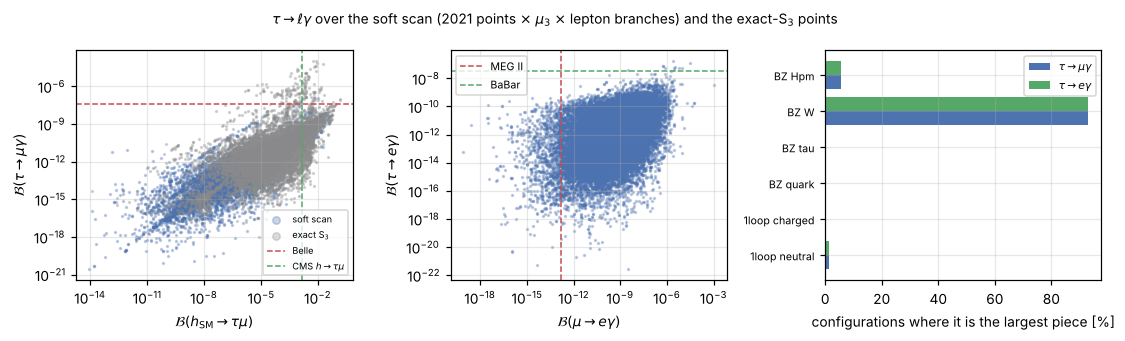

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(10.2, 3.1))
sub = np.random.default_rng(1).choice(len(flat), min(40000, len(flat)), replace=False)
axs[0].scatter(h_tm[sub], br["tau_mu"][sub], s=1.5, alpha=0.3, color=C_BLUE, rasterized=True, label="soft scan")
exs = np.random.default_rng(2).choice(len(ex_b), min(20000, len(ex_b)), replace=False)
axs[0].scatter(ex_h[exs], ex_b[exs], s=1.5, alpha=0.3, color=C_GREY, rasterized=True, label="exact S$_3$")
axs[0].axhline(LIM["tau_mu"], color=C_RED, ls="--", lw=1, label="Belle")
axs[0].axvline(LIMIT["taumu"], color=C_GREEN, ls="--", lw=1, label=r"CMS $h\to\tau\mu$")
axs[0].set_xscale("log"); axs[0].set_yscale("log")
axs[0].set_xlabel(r"$\mathcal{B}(h_{\rm SM}\to\tau\mu)$"); axs[0].set_ylabel(r"$\mathcal{B}(\tau\to\mu\gamma)$")
axs[0].legend(fontsize=6, loc="lower right", markerscale=4)

axs[1].scatter(br["mu_e"][sub], br["tau_e"][sub], s=1.5, alpha=0.3, color=C_BLUE, rasterized=True)
axs[1].axvline(LIM["mu_e"], color=C_RED, ls="--", lw=1, label="MEG II")
axs[1].axhline(LIM["tau_e"], color=C_GREEN, ls="--", lw=1, label="BaBar")
axs[1].set_xscale("log"); axs[1].set_yscale("log")
axs[1].set_xlabel(r"$\mathcal{B}(\mu\to e\gamma)$"); axs[1].set_ylabel(r"$\mathcal{B}(\tau\to e\gamma)$")
axs[1].legend(fontsize=7, loc="upper left")

labels = list(S.MEG_PARTS)
yy = np.arange(len(labels))
axs[2].barh(yy - 0.2, [100 * lead["tau_mu"][q] for q in labels], height=0.4, color=C_BLUE, label=r"$\tau\to\mu\gamma$")
axs[2].barh(yy + 0.2, [100 * lead["tau_e"][q] for q in labels], height=0.4, color=C_GREEN, label=r"$\tau\to e\gamma$")
axs[2].set_yticks(yy); axs[2].set_yticklabels([l.replace("_", " ") for l in labels], fontsize=7)
axs[2].set_xlabel("configurations where it is the largest piece [%]")
axs[2].legend(fontsize=7)
fig.suptitle(r"$\tau\to\ell\gamma$ over the soft scan (" + str(len(points)) + r" points $\times$ $\mu_3$ $\times$ lepton branches) and the exact-S$_3$ points", fontsize=9)
fig.tight_layout()
plt.show()

---
## 6. Deliverable

In [ ]:
out = Path("results/tau_l_gamma.json")


def _round(o):
    "4 significant figures: the JSON is a record of the scan, not an input to anything."
    if isinstance(o, dict):
        return {k_: _round(v_) for k_, v_ in o.items()}
    if isinstance(o, (list, tuple)):
        return [_round(v_) for v_ in o]
    if isinstance(o, (float, np.floating)):
        return float("%.4g" % o)
    if isinstance(o, np.integer):
        return int(o)
    return o


def best_of(rows, name):
    if not rows:
        return None
    x = min(rows, key=lambda x: x["br"][name])
    return {"mu3": x["mu3"], "kind": x["kind"], "br": x["br"], "lead": x["lead"][name]}


payload = {
    "description": ("B(tau -> mu gamma), B(tau -> e gamma) (and B(mu -> e gamma), recomputed) at the " + str(len(points)) + " soft-broken "
                    "viable points of viable_points_soft.json over notebook 06's mu_3 grid and every lepton branch, "
                    "and at the " + str(n_ex) + " exact-S3 points of notebook 01 on the draft branch. Same diagrams as "
                    "notebook 07 (mu_e_gamma.json). Per soft point: the least-constrained configuration of each "
                    "tau channel, and the number allowed by each limit."),
    "conventions": {"limits_90cl": LIM, "br_tau_lnn": {"e": BR_TAU_ENUNU, "mu": BR_TAU_MUNUNU},
                    "alpha": ALPHA, "G_F_GeV-2": G_F, "m_t_GeV": M_T,
                    "mu3_grid_GeV": [float(grid[0]), float(grid[-1]), len(grid)],
                    "mu3_grid_exact_GeV": [float(grid_exact[0]), float(grid_exact[-1]), len(grid_exact)],
                    "quark_couplings": "y_qq(h_i) = kappa_i m_q / v, none for A (ansatz)",
                    "neglected": ["phi Z gamma Barr-Zee", "H+- W gamma Barr-Zee", "HKZ13 set C"],
                    "h_lfv_limits": LIMIT},
    "summary": {"n_configurations": n_cfg,
                "median_br": {name: float(np.median(br[name])) for name in CH},
                "frac_configurations_over_limit": {name: float((~okc[name]).mean()) for name in CH},
                "n_points_allowed": pt,
                "n_points_allowed_all_radiative_variants": pt_var,
                "largest_piece_share": lead,
                "exact": {"n_points": n_ex, "n_evaluations": len(ex_rows),
                          "max_br_tau_e": worst_e, "median_br_tau_mu": float(np.median(ex_b)),
                          "frac_over_belle": float(over_b.mean()), "frac_over_cms_taumu": float(over_h.mean()),
                          "n_over_belle_under_cms": int((over_b & ~over_h).sum()),
                          "n_points_allowed": pt_ex}},
    "points": [{"point": i, "phi": points[i]["phi"], "n_configurations": len(rows),
                "best_tau_mu": best_of(rows, "tau_mu"), "best_tau_e": best_of(rows, "tau_e"),
                "n_allowed": {name: sum(1 for x in rows if x["br"][name] < LIM[name]) for name in CH}}
               for i, rows in enumerate(scan)],
}
out.write_text(json.dumps(_round(payload), separators=(",", ":"), default=float))
print("wrote %s (%.0f kB)" % (out, out.stat().st_size / 1024))

wrote results/tau_l_gamma.json (651 kB)


In [ ]:
ledger.step(r"$\ell_i\to\ell_j\gamma$ amplitudes for general $(i,j)$",
            obtained="derived",
            statement=r"c_L=\sum_f\frac{\tfrac12I_1(t_f)(m_jY_{jf}Y^*_{if}+m_iY^*_{fj}Y_{fi})+I_2(t_f)m_fY^*_{fj}Y^*_{if}}{4m_im_\phi^2}",
            checks=(r"$(\mu,e)$ reproduces notebook 07's stored results at 25 points",
                    r"flavour relabelling maps $(\tau,\ell)$ onto the $(\mu,e)$ code exactly",
                    r"[HKZ13] (A3) with external masses kept, for $\tau\to\mu\gamma$, at 700 and 25 GeV",
                    r"[OST16] (19), the explicit $\tau\to\mu\gamma$ one loop"),
            falsified_by=r"an $m_\tau/m_\mu$ flip factor carried over from $\mu\to e\gamma$ (falsify run)", section="1")
ledger.step(r"$\mathcal B(\tau\to\ell\gamma)=48\pi^3\alpha(|A_L|^2+|A_R|^2)/G_F^2\times\mathcal B(\tau\to\ell\nu\bar\nu)$",
            obtained="imported",
            checks=(r"equals the [HKZ13] lifetime normalization to below 1 percent",
                    r"reproduces both [HKZ13] $\tau$ bounds with their $W$ number"),
            falsified_by=r"the two-loop pieces with the wrong relative sign (falsify run)", section="2 ([OST16] (17))")
ledger.step(r"Residual $\mathbb Z_2$: $\tau\to e\gamma=0$, $\tau\to\mu\gamma\neq0$ at the exact vacuum",
            obtained="derived",
            checks=(r"$\mathcal B(\tau\to e\gamma)<10^{-24}$ at " + str(n_ex) + r" exact points $\times$ 60 values of $\mu_3$",
                    r"3 odd states without $\tau\mu$, 4 even states without $e$ couplings, at every evaluation",
                    r"$\mathcal B(\tau\to e\gamma)\propto(60^\circ-\varphi)^2$ off the alignment",
                    r"all three channels identical at the S$_3$ image (20 points)"),
            section="3-4")
ledger.step(r"Quark couplings along the vacuum direction",
            obtained="assumed",
            checks=(r"same ansatz as notebooks 06 and 07; three variants bound its effect",), section="5")
ledger.table()
ledger.to_latex("derivations_08.tex", subtitle="tau to mu gamma and tau to e gamma")

### Derivation ledger — 08 — the radiative decays of the tau in the soft-broken vacuum

**1. $\ell_i\to\ell_j\gamma$ amplitudes for general $(i,j)$**  
<sub>derived here &nbsp;·&nbsp; §1</sub>

$$c_L=\sum_f\frac{\tfrac12I_1(t_f)(m_jY_{jf}Y^*_{if}+m_iY^*_{fj}Y_{fi})+I_2(t_f)m_fY^*_{fj}Y^*_{if}}{4m_im_\phi^2}$$

- ✓ $(\mu,e)$ reproduces notebook 07's stored results at 25 points
- ✓ flavour relabelling maps $(\tau,\ell)$ onto the $(\mu,e)$ code exactly
- ✓ [HKZ13] (A3) with external masses kept, for $\tau\to\mu\gamma$, at 700 and 25 GeV
- ✓ [OST16] (19), the explicit $\tau\to\mu\gamma$ one loop

*Would be falsified by:* an $m_\tau/m_\mu$ flip factor carried over from $\mu\to e\gamma$ (falsify run)


---

**2. $\mathcal B(\tau\to\ell\gamma)=48\pi^3\alpha(|A_L|^2+|A_R|^2)/G_F^2\times\mathcal B(\tau\to\ell\nu\bar\nu)$**  
<sub>**imported** &nbsp;·&nbsp; §2 ([OST16] (17))</sub>

- ✓ equals the [HKZ13] lifetime normalization to below 1 percent
- ✓ reproduces both [HKZ13] $\tau$ bounds with their $W$ number

*Would be falsified by:* the two-loop pieces with the wrong relative sign (falsify run)


---

**3. Residual $\mathbb Z_2$: $\tau\to e\gamma=0$, $\tau\to\mu\gamma\neq0$ at the exact vacuum**  
<sub>derived here &nbsp;·&nbsp; §3-4</sub>

- ✓ $\mathcal B(\tau\to e\gamma)<10^{-24}$ at 1964 exact points $\times$ 60 values of $\mu_3$
- ✓ 3 odd states without $\tau\mu$, 4 even states without $e$ couplings, at every evaluation
- ✓ $\mathcal B(\tau\to e\gamma)\propto(60^\circ-\varphi)^2$ off the alignment
- ✓ all three channels identical at the S$_3$ image (20 points)

---

**4. Quark couplings along the vacuum direction**  
<sub>**assumed** &nbsp;·&nbsp; §5</sub>

- ✓ same ansatz as notebooks 06 and 07; three variants bound its effect

---

<sub>4 steps: 2 derived here, 1 imported, 1 assumed</sub>

wrote derivations_08.tex  (4 steps)


'derivations_08.tex'

---
## 7. Findings

1. **The generalization to $\ell_i\to\ell_j\gamma$ is checked, not assumed** (§1–§2).
   - With $(i,j)=(\mu,e)$ the refactored code gives back notebook 07's stored results.
   - A flavour relabelling maps the τ channels onto the μ→eγ code exactly.
   - For a decaying τ the closed-form one loop matches [HKZ13] (A3) with the external masses
     kept, to $2\times10^{-3}$ at 25 GeV and $1.3\times10^{-2}$ at the lightest scalar met
     here (6.7 GeV). It also reproduces [OST16]'s explicit τ→μγ Eq. (19).
   - The τ normalization, $\times\mathcal B(\tau\to\ell\nu\bar\nu)$ ([OST16] Eq. (17)), agrees
     with [HKZ13]'s lifetime normalization to 0.2%.
   - The assembled rates reproduce both [HKZ13] τ bounds, 0.016 and 0.014, with their $W$
     number. This oracle also fixes the relative sign of the one and two loops.
   - For an SM-like Higgs the current limits need
     $\sqrt{|Y_{\tau\mu}|^2+|Y_{\mu\tau}|^2}<0.013$, while CMS $h\to\tau\mu$ needs 0.0011. In the
     τ sector **the Higgs decay is about 12× stronger in the coupling**, the reverse of the
     $e\mu$ sector.

2. **The exact-S₃ vacuum splits the τ channels, as the residual $\mathbb Z_2$ predicts** (§3).
   - τ→eγ, which has one odd lepton, is round-off ($<4\times10^{-33}$) at all 1973 exact points
     × 60 values of $\mu_3$, although $e\tau$ couplings reach 0.09.
   - Every evaluation shows the coupling pattern behind this: three odd states with no $\tau\mu$
     coupling and four even states with no electron coupling.
   - Off the alignment, $\mathcal B(\tau\to e\gamma)\propto(60^\circ-\varphi)^2$ (fitted slope
     2.00).
   - τ→μγ is **allowed** and generic: median $2.1\times10^{-11}$, maximum $1.1\times10^{-4}$.
     It is the first radiative mode that tests the exact points.

3. **At the exact vacuum, Belle removes a thin slice that $h\to\tau\mu$ misses.**
   - Belle excludes 0.72% of the exact configurations, against 18.5% for CMS $h\to\tau\mu$.
   - The τ→μγ exclusion is **not a subset**: 460 configurations at 20 points are over Belle but
     under CMS.
   - In every one of them the one loop dominates, and a non-SM neutral $\mathbb Z_2$-even scalar
     is light (6.7–223 GeV, against a median of 302 GeV over all exact points). Its $\tau\mu$
     coupling enters with $1/m_\phi^2$, and the SM-like Higgs decay cannot see that state.
   - No exact point loses all of its $\mu_3$ range.

4. **In the soft vacuum the τ modes add nothing beyond MEG II** (§5).
   - Over the same 417 992 configurations, the medians are
     $\mathcal B(\tau\to\mu\gamma)=2.2\times10^{-12}$ and $\mathcal B(\tau\to e\gamma)=2.3\times10^{-12}$.
   - Only 0.020% and 0.029% of configurations exceed Belle and BaBar.
   - Every scalar point keeps a τ-allowed configuration. Adding both τ limits to MEG II leaves
     notebook 07's counts unchanged: 618, and 606 with the $h\to\ell\ell'$ limits. This holds
     under all three systematic variants (504, 453, 684).
   - Measured against its own limit, τ→μγ is a median $9\times10^{-3}$ as restrictive as
     $h\to\tau\mu$ in the same configuration. Only 108 configurations are excluded by a τ mode
     and allowed by every Higgs limit.
   - The $W$-loop Barr–Zee diagram dominates the τ channels too, as the largest piece in 93% of
     configurations.

5. **A prediction for Belle II.**
   - $\mathcal B(\tau\to e\gamma)/\mathcal B(\mu\to e\gamma)$ has median $2.8\times10^{-3}$. In
     MEG-allowed configurations the τ rates stay at or below $7.5\times10^{-10}$.
   - Where every radiative and Higgs LFV limit holds, the largest values are
     $\mathcal B(\tau\to\mu\gamma)=4.8\times10^{-10}$ and $\mathcal B(\tau\to e\gamma)=3.9\times10^{-10}$.
     That is about 15× and 23× below Belle II's projected 50 ab⁻¹ reach ($6.9\times10^{-9}$ and
     $9.0\times10^{-9}$ [BelleII22]).
   - With this model's soft vacuum and the quark ansatz, **a τ→ℓγ signal at Belle II would
     exclude it**. The exception is the light-scalar corner of the exact vacuum (finding 3).

## Open questions

- The diagrams left out in notebook 07 ([HKZ13] set C, $\phi Z\gamma$ and $H^\pm W\gamma$
  Barr–Zee) and the quark ansatz carry over unchanged. The soft-vacuum conclusion (no new
  points removed) has a margin of about $10^2$, so they cannot reverse it.
- **The light-scalar corner.** The exact-vacuum τ→μγ exclusions sit at non-SM neutral even
  scalars below ~220 GeV. Their LEP/LHC direct-search status (notebook 01 cuts only on the
  $hVV$ coupling) would say whether this corner is already closed.
- **τ→3μ, τ→μee** share the τμ dipole and add tree-level contact terms through the
  same scalars.

In [ ]:
check_quoted("7", [
    ("HKZ tau mu bound", rel_hkz["tau_mu"], 0.0, 0.035),
    ("tau mu bound, current", cur["tau_mu"], 0.013, 0.0005),
    ("CMS coupling bound tau mu", y_h["taumu"], 0.0011, 0.00005),
    ("closed form at the lightest scalar /1e-2", rel_low / 1e-2, 1.3, 0.05),
    ("lightest scalar GeV", m_low, 6.7, 0.05),
    ("exact median B(tau mu) /1e-11", np.median(ex_b) / 1e-11, 2.1, 0.05),
    ("exact max B(tau mu) /1e-4", ex_b.max() / 1e-4, 1.1, 0.05),
    ("% exact over Belle", 100 * over_b.mean(), 0.72, 0.005),
    ("% exact over CMS", 100 * over_h.mean(), 18.5, 0.05),
    ("exact over Belle under CMS", (over_b & ~over_h).sum(), 460, 0),
    ("exact points in them", len(set(ex_n[over_b & ~over_h])), 20, 0),
    ("slope", slope, 2.0, 0.01),
    ("configurations", n_cfg, 417992, 0),
    ("soft median B(tau mu) /1e-12", np.median(br["tau_mu"]) / 1e-12, 2.2, 0.05),
    ("soft median B(tau e) /1e-12", np.median(br["tau_e"]) / 1e-12, 2.3, 0.05),
    ("% over Belle", 100 * (~okc["tau_mu"]).mean(), 0.020, 0.0005),
    ("% over BaBar", 100 * (~okc["tau_e"]).mean(), 0.029, 0.0005),
    ("points tau both", pt["tau_both"], 2028, 0),
    ("points all radiative", pt["all_rad"], 618, 0),
    ("points all radiative + h", pt["all_rad_h"], 606, 0),
    ("median ratio tau mu /1e-3", np.median(r_tm) / 1e-3, 9.2, 0.05),
    ("tau-excluded, h-allowed", ((~(okc["tau_mu"] & okc["tau_e"])) & h_ok).sum(), 108, 0),
    ("% BZ_W largest tau mu", 100 * lead["tau_mu"]["BZ_W"], 93, 0.5),
    ("median tau e / mu e /1e-3", np.median(ratio_te) / 1e-3, 2.8, 0.05),
    ("max tau mu MEG-allowed /1e-10", br["tau_mu"][meg_ok].max() / 1e-10, 7.5, 0.05),
    ("max tau mu allowed /1e-10", br["tau_mu"][all_ok].max() / 1e-10, 4.8, 0.05),
    ("max tau e allowed /1e-10", br["tau_e"][all_ok].max() / 1e-10, 3.9, 0.05),
    ("variant no_quark", pt_var["no_quark"], 504, 0),
    ("variant top_flip", pt_var["top_flip"], 453, 0),
    ("variant w_hkz", pt_var["w_hkz"], 684, 0),
])

✓ the 30 numbers quoted in §7 match this run


---
## 8. References

- **[OST16]** Y. Omura, E. Senaha, K. Tobe, *"τ- and μ-physics in a general two Higgs doublet
  model with μ−τ flavor violation"*, Phys. Rev. D **94**, 055019 (2016),
  [arXiv:1511.08880](https://arxiv.org/abs/1511.08880). Eq. (17) the τ→μγ branching ratio,
  Eqs. (18)–(19) its one loop.
- **[HKZ13]** R. Harnik, J. Kopp, J. Zupan, *"Flavor violating Higgs decays"*,
  JHEP **03** (2013) 026, [arXiv:1209.1397](https://arxiv.org/abs/1209.1397). Eq. (A3) the
  one-loop integral, Eqs. (14)–(15), the text below them and Table I the τ oracles.
- **[Belle21]** Belle Collaboration, *"Search for lepton-flavor-violating
  tau-lepton decays to ℓγ at Belle"*, JHEP **10** (2021) 019,
  [arXiv:2103.12994](https://arxiv.org/abs/2103.12994). $\mathcal B(\tau\to\mu\gamma)<4.2\times10^{-8}$,
  $\mathcal B(\tau\to e\gamma)<5.6\times10^{-8}$ at 90% CL.
- **[BaBar10]** BaBar Collaboration, *"Searches for lepton flavor
  violation in the decays τ±→e±γ and τ±→μ±γ"*, Phys. Rev. Lett. **104**, 021802 (2010),
  [arXiv:0908.2381](https://arxiv.org/abs/0908.2381). $\mathcal B(\tau\to e\gamma)<3.3\times10^{-8}$,
  $\mathcal B(\tau\to\mu\gamma)<4.4\times10^{-8}$ at 90% CL.
- **[BelleII22]** Belle II, *"Searches for lepton flavor violation in tau decays at Belle II"*,
  [arXiv:2209.11639](https://arxiv.org/abs/2209.11639). Expected limits at 50 ab⁻¹:
  $6.9\times10^{-9}$ (μγ), $9.0\times10^{-9}$ (eγ).
- **[MEGII25]**, **[CMS21]**, **[CMS23]**, **[Ilisie15]**, **[Lavoura03]** as in notebook 07.
- **[PDG]** S. Navas *et al.*, Phys. Rev. D **110**, 030001 (2024): $\mathcal B(\tau\to e\nu\bar\nu)=17.82\%$,
  $\mathcal B(\tau\to\mu\nu\bar\nu)=17.39\%$, $\tau_\tau=290.3$ fs, and the inputs of `sm_inputs.py`.